# 20 · Pruebas de carga y monitoreo del servicio EmoGol

Este notebook evalúa el servicio de inferencia con `emogol.joblib` como pide la actividad 11 del anteproyecto y el protocolo del informe de evaluación: tráfico generado a tasas crecientes, medición de latencia, telemetría de recursos con Prometheus y caché en Redis.

**Qué se mide**

1. **Barrido de carga** (chat y comentarios): la tasa sube por niveles de 120 s hasta la saturación. En cada nivel: mensajes clasificados por segundo, latencia p50/p95/p99, cola, tamaño de lote, uso de GPU, memoria de GPU, uso de CPU y RAM. En el escenario de comentarios se guarda la respuesta de cada mensaje para calcular la **accuracy bajo carga**.
2. **Caché en Redis**: cuántos mensajes se repiten en los datos reales y cuánto cambia la latencia de una ráfaga con y sin caché.
3. **Latencia de punta a punta**: se reproduce el chat real con sus tiempos de publicación y una ingesta que consulta YouTube cada 10 s, como el notebook 17.
4. **Monitoreo con Prometheus**: Prometheus recoge las métricas del servicio (`/metrics`) cada 2 s durante todo el notebook; al final se grafican como los paneles del tablero de Grafana incluido en `emogol_app/despliegue/`.

Un nivel está **saturado** cuando el servicio clasifica menos del 90 % de lo que recibe, la latencia crece durante el nivel o aparecen errores. La tasa real del chat de la final Sub-20 fue de 1,12 mensajes/s.

**Entorno:** Google Colab con GPU T4. **Duración:** unos 60 minutos; no cerrar la pestaña. **Secretos:** `HF_TOKEN`.
**Resultado:** tablas y gráficas en `emotion-futbol-data/prototipo/pruebas_carga/`.

In [2]:
!pip install -q -U transformers accelerate peft bitsandbytes "huggingface_hub<2.0" "pandas<3" joblib fastapi uvicorn httpx redis prometheus_client psutil nvidia-ml-py
!pip uninstall -y -q torchao
!apt-get -qq install -y redis-server > /dev/null
!wget -q https://github.com/prometheus/prometheus/releases/download/v2.55.1/prometheus-2.55.1.linux-amd64.tar.gz && tar xzf prometheus-2.55.1.linux-amd64.tar.gz
!rm -rf emotion_futbol && git clone -q https://github.com/santiagortegasegura/emotion_futbol.git
!pip install -q -e "emotion_futbol/emogol_app[servicio]"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-sdk 1.42.1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.45.2 which is incompatible.
opentelemetry-semantic-conventions 0.63b1 requires opentelemetry-api==1.42.1, but you have opentelemetry-api 1.45.2 which is incompatible.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for emogol (pyproject.toml) ... done


In [3]:
import os, sys
from google.colab import userdata
from huggingface_hub import login

os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
login(token=os.environ["HF_TOKEN"])

USUARIO_HF = "santiagortegasegura"
REPO_MODELO = f"{USUARIO_HF}/emogol-2b"
REPO_DATOS = f"{USUARIO_HF}/emotion-futbol-data"
APP = "/content/emotion_futbol/emogol_app"
sys.path.insert(0, APP)

TASAS_CHAT = [0.5, 1.12, 2, 3, 4, 5, 6, 8, 10]     # mensajes por segundo
TASAS_COMENTARIOS = [0.5, 1, 2, 3, 4, 5, 6]
DURACION_NIVEL = 120                               # segundos de envío por nivel
INTERVALO_INGESTA = 10                             # segundos entre consultas al chat de YouTube (notebook 17)
PUERTO = 8000

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


## 1. Levantar Redis, Prometheus y el servicio con `emogol.joblib`

In [4]:
import subprocess, time, httpx
from huggingface_hub import hf_hub_download

subprocess.run(["redis-server", "--daemonize", "yes", "--maxmemory", "256mb", "--maxmemory-policy", "allkeys-lru"], check=True)

def iniciar_prometheus():
    """Arranca Prometheus y espera a que esté listo. Si falla, las pruebas siguen sin él."""
    binario = "/content/prometheus-2.55.1.linux-amd64/prometheus"
    if not os.path.exists(binario):
        subprocess.run("wget -q https://github.com/prometheus/prometheus/releases/download/v2.55.1/"
                       "prometheus-2.55.1.linux-amd64.tar.gz -O /content/prom.tgz && tar xzf /content/prom.tgz -C /content",
                       shell=True)
    config = "/content/prometheus_local.yml"
    open(config, "w").write("global:\n  scrape_interval: 2s\nscrape_configs:\n  - job_name: emogol\n"
                            "    static_configs:\n      - targets: ['127.0.0.1:8000']\n")
    proceso = subprocess.Popen([binario, f"--config.file={config}", "--storage.tsdb.path=/content/prometheus_datos",
                                "--web.listen-address=127.0.0.1:9090"],
                               stdout=open("/content/prometheus.log", "w"), stderr=subprocess.STDOUT)
    for _ in range(30):
        try:
            if httpx.get("http://127.0.0.1:9090/-/ready", timeout=2).status_code == 200:
                return proceso, True
        except Exception:
            time.sleep(2)
    print("Prometheus no arrancó; las pruebas siguen sin él. Últimas líneas del registro:")
    print(open("/content/prometheus.log").read()[-1000:])
    return proceso, False

ruta_joblib = hf_hub_download(REPO_MODELO, "emogol.joblib")
entorno = {**os.environ, "EMOGOL_JOBLIB": ruta_joblib, "PYTHONPATH": APP, "REDIS_URL": "redis://127.0.0.1:6379/0"}
servidor = subprocess.Popen(["python", "-m", "uvicorn", "api.main:app", "--host", "127.0.0.1", "--port", str(PUERTO)],
                            cwd=APP, env=entorno, stdout=open("servidor.log", "w"), stderr=subprocess.STDOUT)
URL = f"http://127.0.0.1:{PUERTO}"
for _ in range(120):
    try:
        salud = httpx.get(f"{URL}/salud", timeout=2).json(); break
    except Exception:
        time.sleep(5)
else:
    raise RuntimeError(open("servidor.log").read()[-2000:])
prometheus, PROMETHEUS_OK = iniciar_prometheus()
INICIO_PRUEBAS = time.time()
print(salud)
print("Prometheus listo:", PROMETHEUS_OK)

emogol.joblib: reconstructing file:   0%|          |  0.00B / 46.6MB            

emogol.joblib: downloading bytes:           |  0.00B            

{'estado': 'ok', 'segundos_carga': 97.8, 'modelo': {'version': '1.0.0', 'modelo_base': 'google/gemma-2-2b-it', 'adaptador': 'santiagortegasegura/emotion-futbol-checkpoints/gemma2_2b/adapter_final', 'tamano_adaptador_mib': 112.0, 'huella_adaptador': '901218559d5ff61d', 'cargado': True, 'bits': 4, 'creado': '2026-11-17T16:44:22+00:00', 'origen': 'https://huggingface.co/datasets/santiagortegasegura/emotion-futbol-checkpoints'}, 'cache_redis': True, 'metricas_prometheus': True}
Prometheus listo: True


## 2. Mensajes de prueba

In [5]:
import pandas as pd

chat = pd.read_csv(hf_hub_download(REPO_DATOS, "prototipo/en_vivo_prueba/en_vivo_prueba_chat_clasificado.csv",
                                   repo_type="dataset"), keep_default_na=False)
prueba = pd.read_csv(hf_hub_download(REPO_DATOS, "final/prueba_final_10k.csv", repo_type="dataset"),
                     keep_default_na=False)
final = pd.read_csv(hf_hub_download(REPO_DATOS, "prototipo/mundial2026_prueba/mundial2026_prueba_comentarios_clasificados.csv",
                                    repo_type="dataset"), keep_default_na=False)

chat["created_at"] = pd.to_datetime(chat["created_at"], utc=True)
chat = chat.sort_values("created_at").reset_index(drop=True)
textos_chat = chat["text"].astype(str).tolist()
muestra = prueba.sample(2000, random_state=42)
textos_comentarios = muestra["text"].astype(str).tolist()
etiquetas_comentarios = muestra["label"].astype(str).tolist()
final["created_at"] = pd.to_datetime(final["created_at"], utc=True)
textos_final = final.sort_values("created_at")["text"].astype(str).tolist()
print(f"Chat: {len(textos_chat)} mensajes (mediana {chat['text'].str.len().median():.0f} caracteres)")
print(f"Comentarios de la prueba: {len(textos_comentarios)} (mediana {muestra['text'].str.len().median():.0f} caracteres)")
print(f"Final de la Copa del Mundo: {len(textos_final)} comentarios")

en_vivo_prueba_chat_clasificado.csv:   0%|          | 0.00/30.0k [00:00<?, ?B/s]

prueba_final_10k.csv:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

(…)2026_prueba_comentarios_clasificados.csv:   0%|          | 0.00/590k [00:00<?, ?B/s]

Chat: 269 mensajes (mediana 15 caracteres)
Comentarios de la prueba: 2000 (mediana 57 caracteres)
Final de la Copa del Mundo: 3000 comentarios


## 3. Latencia de un mensaje aislado

In [6]:
import statistics
lat = []
with httpx.Client(timeout=60) as cliente:
    for texto in textos_chat[:50]:
        t0 = time.perf_counter()
        cliente.post(f"{URL}/clasificar", json={"textos": [texto], "fuente": "chat", "usar_cache": False})
        lat.append(1000 * (time.perf_counter() - t0))
print(f"Latencia uno a uno: mediana {statistics.median(lat):.0f} ms | p95 {sorted(lat)[int(0.95 * len(lat))]:.0f} ms")

Latencia uno a uno: mediana 783 ms | p95 999 ms


## 4. Barrido de carga: chat en vivo (sin caché)

In [7]:
from pruebas_carga.generador import barrido, clasificar_niveles, rafaga, fin_a_fin

resultados_chat = clasificar_niveles(await barrido(URL, textos_chat, TASAS_CHAT, DURACION_NIVEL, "chat"))
resultados_chat

[chat]   0.5 msg/s -> logrado   0.5 msg/s | p50 824.6 ms | p95 1018.2 ms | cola máx 1 | GPU 18.4 % | CPU 37.6 % | ok
[chat]  1.12 msg/s -> logrado  1.11 msg/s | p50 1138.1 ms | p95 1533.7 ms | cola máx 2 | GPU 37.6 % | CPU 66.0 % | ok
[chat]     2 msg/s -> logrado  1.98 msg/s | p50 1765.2 ms | p95 2534.8 ms | cola máx 3 | GPU 58.4 % | CPU 68.9 % | ok
[chat]     3 msg/s -> logrado  2.97 msg/s | p50 2015.8 ms | p95 2823.3 ms | cola máx 6 | GPU 73.2 % | CPU 68.7 % | ok
[chat]     4 msg/s -> logrado  3.91 msg/s | p50 3155.8 ms | p95 4465.4 ms | cola máx 11 | GPU 93.0 % | CPU 69.7 % | ok
[chat]     5 msg/s -> logrado  4.79 msg/s | p50 5711.8 ms | p95 7541.3 ms | cola máx 26 | GPU 95.9 % | CPU 70.4 % | ok
[chat]     6 msg/s -> logrado  4.83 msg/s | p50 18189.3 ms | p95 29680.8 ms | cola máx 138 | GPU 95.5 % | CPU 71.6 % | SATURADO
[chat]     8 msg/s -> logrado  4.88 msg/s | p50 40539.3 ms | p95 74944.4 ms | cola máx 379 | GPU 95.6 % | CPU 74.1 % | SATURADO
[chat]    10 msg/s -> logrado  4.83

,escenario,tasa_ofrecida,duracion_s,enviados,completados,errores,rendimiento_logrado,latencia_p50_ms,latencia_p95_ms,latencia_p99_ms,...,uso_gpu_pct,memoria_gpu_mib,uso_cpu_pct,ram_mib,accuracy,cache_tasa_aciertos,usar_cache,cola_creciente,saturado,condicion
0,chat,0.50,120,60,60,0,0.50,824.6,1018.2,1088.1,...,18.4,2647.0,37.6,2769.8,None,None,False,False,False,normal
1,chat,1.12,120,135,135,0,1.11,1138.1,1533.7,1817.2,...,37.6,2647.0,66.0,2765.6,None,None,False,False,False,normal
2,chat,2.00,120,240,240,0,1.98,1765.2,2534.8,2716.0,...,58.4,2647.0,68.9,2772.1,None,None,False,False,False,alta demanda
3,chat,3.00,120,360,360,0,2.97,2015.8,2823.3,3160.5,...,73.2,2649.0,68.7,2780.1,None,None,False,False,False,alta demanda
4,chat,4.00,120,480,480,0,3.91,3155.8,4465.4,4903.6,...,93.0,2735.0,69.7,2775.8,None,None,False,False,False,cercano a la saturación
5,chat,5.00,120,600,600,0,4.79,5711.8,7541.3,8129.5,...,95.9,3043.0,70.4,2783.7,None,None,False,False,False,cercano a la saturación
6,chat,6.00,120,720,720,0,4.83,18189.3,29680.8,30645.4,...,95.5,3043.0,71.6,2779.2,None,None,False,True,True,saturación
7,chat,8.00,120,960,960,0,4.88,40539.3,74944.4,77384.7,...,95.6,3043.0,74.1,2784.9,None,None,False,True,True,saturación
8,chat,10.00,120,1200,1200,0,4.83,67752.0,123204.7,128340.6,...,95.5,3043.0,75.9,2803.1,None,None,False,True,True,saturación


## 5. Barrido de carga: comentarios de video, con accuracy bajo carga (sin caché)

In [8]:
resultados_com = clasificar_niveles(await barrido(URL, textos_comentarios, TASAS_COMENTARIOS, DURACION_NIVEL,
                                                 "comentarios", etiquetas=etiquetas_comentarios), tasa_real=1.12)
resultados_com

[comentarios]   0.5 msg/s -> logrado   0.5 msg/s | p50 987.0 ms | p95 1268.4 ms | cola máx 1 | GPU 19.0 % | CPU 45.5 % | acc 0.8 | ok
[comentarios]     1 msg/s -> logrado   1.0 msg/s | p50 1133.5 ms | p95 1577.9 ms | cola máx 1 | GPU 37.0 % | CPU 66.3 % | acc 0.8083 | ok
[comentarios]     2 msg/s -> logrado  1.98 msg/s | p50 1882.8 ms | p95 2672.3 ms | cola máx 3 | GPU 61.8 % | CPU 68.8 % | acc 0.8208 | ok
[comentarios]     3 msg/s -> logrado  2.96 msg/s | p50 2681.1 ms | p95 3961.5 ms | cola máx 8 | GPU 84.4 % | CPU 69.6 % | acc 0.85 | ok
[comentarios]     4 msg/s -> logrado  3.73 msg/s | p50 7123.9 ms | p95 10417.1 ms | cola máx 30 | GPU 95.5 % | CPU 70.9 % | acc 0.8583 | SATURADO
[comentarios]     5 msg/s -> logrado  3.75 msg/s | p50 22505.8 ms | p95 39476.5 ms | cola máx 149 | GPU 96.1 % | CPU 71.6 % | acc 0.855 | SATURADO
[comentarios]     6 msg/s -> logrado  3.76 msg/s | p50 37482.0 ms | p95 69522.7 ms | cola máx 270 | GPU 96.5 % | CPU 73.7 % | acc 0.85 | SATURADO


,escenario,tasa_ofrecida,duracion_s,enviados,completados,errores,rendimiento_logrado,latencia_p50_ms,latencia_p95_ms,latencia_p99_ms,...,uso_gpu_pct,memoria_gpu_mib,uso_cpu_pct,ram_mib,accuracy,cache_tasa_aciertos,usar_cache,cola_creciente,saturado,condicion
0,comentarios,0.5,120,60,60,0,0.50,987.0,1268.4,1281.1,...,19.0,3043.0,45.5,2799.2,0.8000,None,False,False,False,normal
1,comentarios,1.0,120,120,120,0,1.00,1133.5,1577.9,1681.4,...,37.0,3043.0,66.3,2798.3,0.8083,None,False,False,False,normal
2,comentarios,2.0,120,240,240,0,1.98,1882.8,2672.3,2856.2,...,61.8,3043.0,68.8,2800.7,0.8208,None,False,False,False,alta demanda
3,comentarios,3.0,120,360,360,0,2.96,2681.1,3961.5,4452.6,...,84.4,3043.0,69.6,2795.5,0.8500,None,False,False,False,cercano a la saturación
4,comentarios,4.0,120,480,480,0,3.73,7123.9,10417.1,11774.5,...,95.5,3043.0,70.9,2796.3,0.8583,None,False,False,True,saturación
5,comentarios,5.0,120,600,600,0,3.75,22505.8,39476.5,41448.8,...,96.1,3043.0,71.6,2799.8,0.8550,None,False,True,True,saturación
6,comentarios,6.0,120,720,720,0,3.76,37482.0,69522.7,72629.0,...,96.5,3043.0,73.7,2803.5,0.8500,None,False,True,True,saturación


## 6. Caché en Redis

Primero se cuenta cuántos mensajes repiten exactamente un texto anterior en los datos reales: esa es la fracción que la caché puede responder sin usar la GPU. Luego se envía cada conjunto una sola vez, en su orden real, como una ráfaga, con y sin caché.

In [9]:
def repetidos(textos):
    vistos, rep = set(), 0
    for t in textos:
        rep += t.strip() in vistos
        vistos.add(t.strip())
    return rep / len(textos)

reps = {"chat": repetidos(textos_chat), "final": repetidos(textos_final)}
print(f"Mensajes repetidos: chat {reps['chat']:.1%} | comentarios de la final {reps['final']:.1%}")

filas = []
for nombre, textos, tasa in [("chat", textos_chat, 5), ("chat", textos_chat, 10), ("final", textos_final[:1000], 6)]:
    for usar in (False, True):
        r = await rafaga(URL, textos, tasa, usar_cache=usar, escenario=f"rafaga_{nombre}")
        filas.append(r.__dict__)
        print(f"{nombre:<6} {tasa:>3} msg/s | caché {'sí' if usar else 'no'} | logrado {r.rendimiento_logrado} msg/s | "
              f"p50 {r.latencia_p50_ms} ms | p95 {r.latencia_p95_ms} ms | aciertos {r.cache_tasa_aciertos}")
        time.sleep(10)
resultados_cache = pd.DataFrame(filas)
resultados_cache

Mensajes repetidos: chat 8.6% | comentarios de la final 0.0%
chat     5 msg/s | caché no | logrado 4.58 msg/s | p50 5658.4 ms | p95 7565.4 ms | aciertos None
chat     5 msg/s | caché sí | logrado 5.02 msg/s | p50 4203.9 ms | p95 6188.6 ms | aciertos 0.0855
chat    10 msg/s | caché no | logrado 4.67 msg/s | p50 18034.4 ms | p95 30151.9 ms | aciertos None
chat    10 msg/s | caché sí | logrado 5.42 msg/s | p50 15690.2 ms | p95 25698.3 ms | aciertos 0.0855
final    6 msg/s | caché no | logrado 3.51 msg/s | p50 61366.6 ms | p95 114883.3 ms | aciertos None
final    6 msg/s | caché sí | logrado 3.51 msg/s | p50 60901.8 ms | p95 114153.7 ms | aciertos 0.0


,escenario,tasa_ofrecida,duracion_s,enviados,completados,errores,rendimiento_logrado,latencia_p50_ms,latencia_p95_ms,latencia_p99_ms,...,lote_promedio,uso_gpu_pct,memoria_gpu_mib,uso_cpu_pct,ram_mib,accuracy,cache_tasa_aciertos,usar_cache,cola_creciente,saturado
0,rafaga_chat,5,53.800000,269,269,0,4.58,5658.4,7565.4,7978.7,...,12.81,94.8,3043.0,70.7,2804.0,None,NaN,False,False,False
1,rafaga_chat,5,53.800000,269,269,0,5.02,4203.9,6188.6,6587.9,...,11.71,92.5,3043.0,72.1,2800.0,None,0.0855,True,False,False
2,rafaga_chat,10,26.900000,269,269,0,4.67,18034.4,30151.9,30946.2,...,14.16,93.1,3043.0,70.2,2799.5,None,NaN,False,True,True
3,rafaga_chat,10,26.900000,269,269,0,5.42,15690.2,25698.3,26487.9,...,14.47,95.3,3043.0,71.2,2802.1,None,0.0855,True,True,True
4,rafaga_final,6,166.666667,1000,1000,0,3.51,61366.6,114883.3,118867.6,...,15.38,97.6,3043.0,73.2,2810.6,None,NaN,False,True,True
5,rafaga_final,6,166.666667,1000,1000,0,3.51,60901.8,114153.7,118339.9,...,15.38,97.6,3043.0,72.9,2825.1,None,0.0000,True,True,True


## 7. Latencia de punta a punta (reproducción del chat real)

Cada mensaje se envía en la consulta a YouTube siguiente a su publicación (cada 10 s). Se mide desde la publicación hasta que el servicio devuelve la emoción. No incluye el tiempo de dibujar el tablero.

In [10]:
publicados = (chat["created_at"] - chat["created_at"].min()).dt.total_seconds().tolist()
e2e = await fin_a_fin(URL, publicados, textos_chat, intervalo=INTERVALO_INGESTA)
resumen_e2e = {c: {"mediana": round(e2e[c].median(), 2), "p95": round(e2e[c].quantile(0.95), 2), "max": round(e2e[c].max(), 2)}
               for c in ["espera_ingesta_s", "servicio_s", "punta_a_punta_s"]}
print(pd.DataFrame(resumen_e2e).T)

                  mediana    p95    max
espera_ingesta_s     4.47   9.28   9.96
servicio_s           2.62   4.07   5.05
punta_a_punta_s      6.92  12.03  14.22


## 8. Monitoreo: series de Prometheus

Las mismas consultas del tablero de Grafana (`emogol_app/despliegue/grafana/dashboards/emogol.json`), leídas de Prometheus para todo el periodo de pruebas.

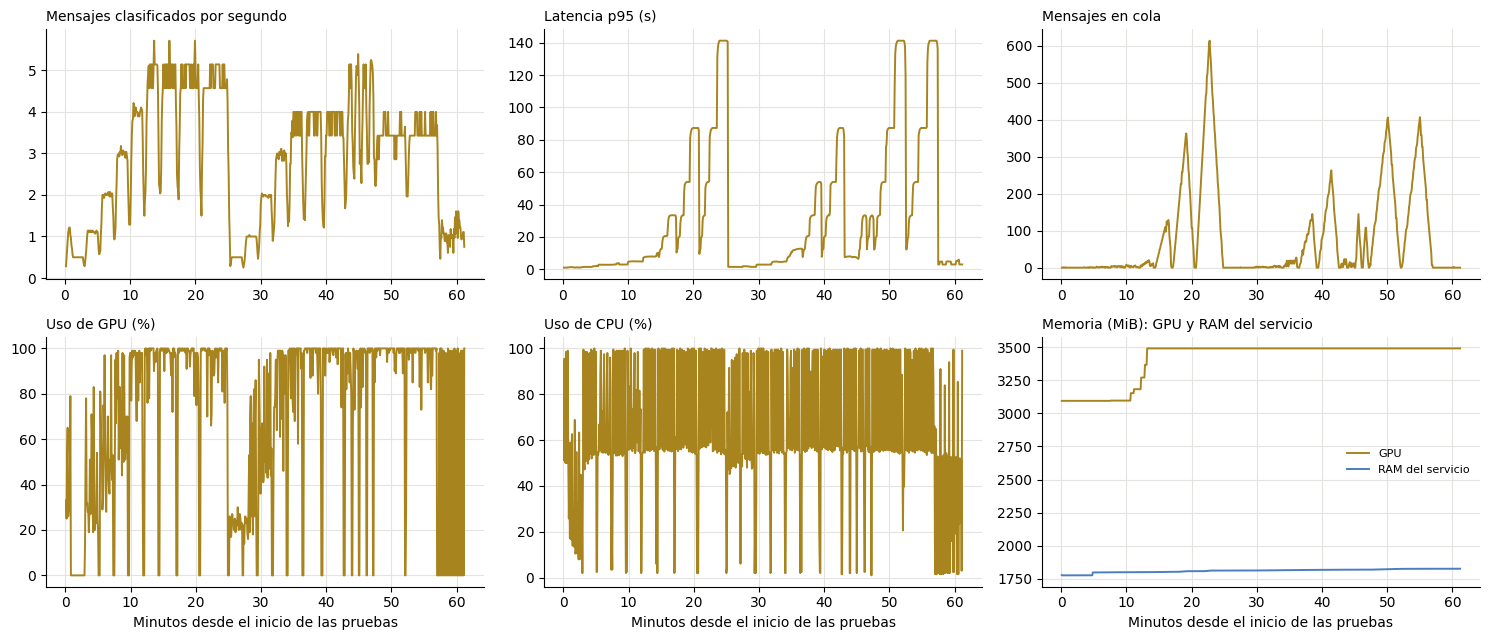

In [11]:
if not PROMETHEUS_OK:
    prometheus, PROMETHEUS_OK = iniciar_prometheus()
import matplotlib.pyplot as plt

def serie(expr, paso=5):
    try:
        r = httpx.get("http://127.0.0.1:9090/api/v1/query_range",
                      params={"query": expr, "start": INICIO_PRUEBAS, "end": time.time(), "step": paso}).json()
        res = r["data"]["result"]
    except Exception:
        return pd.Series(dtype=float)
    if not res:
        return pd.Series(dtype=float)
    v = res[0]["values"]
    return pd.Series([float(x) for _, x in v], index=[(float(t) - INICIO_PRUEBAS) / 60 for t, _ in v])

paneles = [
    ("Mensajes clasificados por segundo", "sum(rate(emogol_mensajes_total[30s]))"),
    ("Latencia p95 (s)", "histogram_quantile(0.95, sum by (le) (rate(emogol_latencia_segundos_bucket[30s])))"),
    ("Mensajes en cola", "emogol_cola_mensajes"),
    ("Uso de GPU (%)", "emogol_gpu_uso_porcentaje"),
    ("Uso de CPU (%)", "emogol_cpu_porcentaje"),
    ("Memoria (MiB): GPU y RAM del servicio", None),
]
fig, ejes = plt.subplots(2, 3, figsize=(15, 6.5))
series_prom = {}
for ax, (titulo, expr) in zip(ejes.flat, paneles):
    if expr:
        s = serie(expr); series_prom[titulo] = s
        ax.plot(s.index, s.values, color="#A8841F", lw=1.4)
    else:
        for e, nombre, col in [("emogol_gpu_memoria_mib", "GPU", "#A8841F"), ("emogol_ram_proceso_mib", "RAM del servicio", "#4A7EBF")]:
            s = serie(e); series_prom[nombre] = s
            ax.plot(s.index, s.values, color=col, lw=1.4, label=nombre)
        ax.legend(frameon=False, fontsize=8)
    ax.set_title(titulo, loc="left", fontsize=10); ax.grid(color="#E4E3DF"); ax.spines[["top", "right"]].set_visible(False)
for ax in ejes[1]:
    ax.set_xlabel("Minutos desde el inicio de las pruebas")
plt.tight_layout(); plt.savefig("monitoreo_prometheus.png", dpi=200); plt.show()
pd.DataFrame(series_prom).to_csv("monitoreo_prometheus.csv")

## 9. Resumen, gráfica y publicación

/tmp/ipykernel_522/1869244776.py:5: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  resultados = pd.concat([resultados_chat, resultados_com], ignore_index=True)


{
  "gpu": "Tesla T4",
  "latencia_uno_a_uno_ms": {
    "mediana": 783.2,
    "p95": 998.6
  },
  "chat": {
    "capacidad_msg_s": 4.88,
    "tasa_saturacion_msg_s": 6.0,
    "veces_tasa_real": 4.4
  },
  "comentarios": {
    "capacidad_msg_s": 3.76,
    "tasa_saturacion_msg_s": 4.0,
    "accuracy_por_nivel": {
      "0.5": 0.8,
      "1.0": 0.8083,
      "2.0": 0.8208,
      "3.0": 0.85,
      "4.0": 0.8583,
      "5.0": 0.855,
      "6.0": 0.85
    }
  },
  "recursos_maximos": {
    "cpu_pct_promedio_max": 75.9,
    "ram_mib_max": 2803.5,
    "vram_mib_max": 3043.0
  },
  "cache": {
    "repetidos_chat": 0.0855,
    "repetidos_final": 0.0
  },
  "punta_a_punta_s": {
    "espera_ingesta_s": {
      "mediana": 4.47,
      "p95": 9.28,
      "max": 9.96
    },
    "servicio_s": {
      "mediana": 2.62,
      "p95": 4.07,
      "max": 5.05
    },
    "punta_a_punta_s": {
      "mediana": 6.92,
      "p95": 12.03,
      "max": 14.22
    }
  },
  "duracion_nivel_s": 120,
  "intervalo_inges

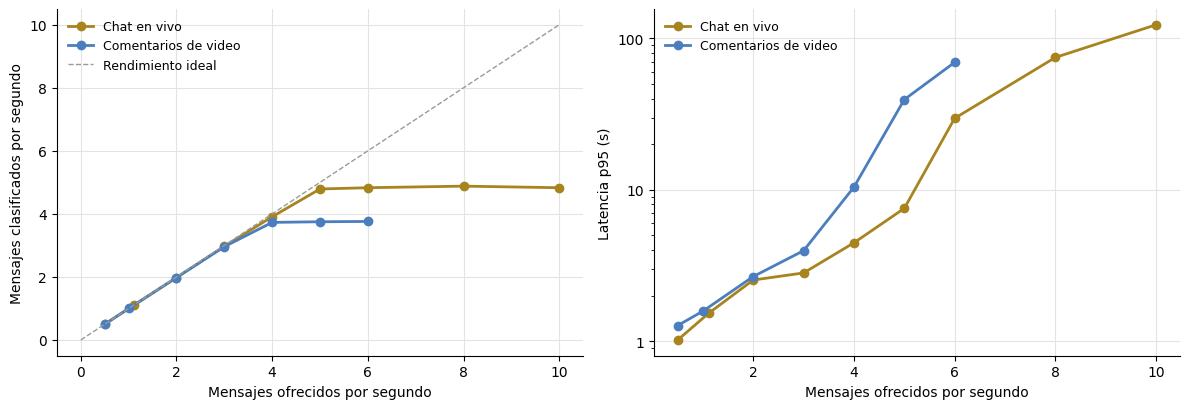

In [12]:
import json, torch
from matplotlib.ticker import FuncFormatter

ORO, AZUL, TINTA, REJILLA = "#A8841F", "#4A7EBF", "#3B3B3B", "#E4E3DF"
resultados = pd.concat([resultados_chat, resultados_com], ignore_index=True)
sat = lambda df: float(df.loc[df["saturado"], "tasa_ofrecida"].min()) if df["saturado"].any() else None
resumen = {
    "gpu": torch.cuda.get_device_name(0),
    "latencia_uno_a_uno_ms": {"mediana": round(statistics.median(lat), 1), "p95": round(sorted(lat)[int(0.95 * len(lat))], 1)},
    "chat": {"capacidad_msg_s": float(resultados_chat["rendimiento_logrado"].max()), "tasa_saturacion_msg_s": sat(resultados_chat),
             "veces_tasa_real": round(float(resultados_chat["rendimiento_logrado"].max()) / 1.12, 1)},
    "comentarios": {"capacidad_msg_s": float(resultados_com["rendimiento_logrado"].max()), "tasa_saturacion_msg_s": sat(resultados_com),
                    "accuracy_por_nivel": dict(zip(resultados_com["tasa_ofrecida"].astype(str), resultados_com["accuracy"]))},
    "recursos_maximos": {"cpu_pct_promedio_max": float(resultados["uso_cpu_pct"].max()), "ram_mib_max": float(resultados["ram_mib"].max()),
                         "vram_mib_max": float(resultados["memoria_gpu_mib"].max())},
    "cache": {"repetidos_chat": round(reps["chat"], 4), "repetidos_final": round(reps["final"], 4)},
    "punta_a_punta_s": resumen_e2e,
    "duracion_nivel_s": DURACION_NIVEL, "intervalo_ingesta_s": INTERVALO_INGESTA,
}
print(json.dumps(resumen, indent=2, ensure_ascii=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
for df, color, nombre in [(resultados_chat, ORO, "Chat en vivo"), (resultados_com, AZUL, "Comentarios de video")]:
    a1.plot(df["tasa_ofrecida"], df["rendimiento_logrado"], "o-", color=color, lw=2, label=nombre)
    a2.plot(df["tasa_ofrecida"], df["latencia_p95_ms"] / 1000, "o-", color=color, lw=2, label=nombre)
a1.plot([0, max(TASAS_CHAT)], [0, max(TASAS_CHAT)], "--", color="#9A9A9A", lw=1, label="Rendimiento ideal")
a1.set_xlabel("Mensajes ofrecidos por segundo"); a1.set_ylabel("Mensajes clasificados por segundo")
a2.set_xlabel("Mensajes ofrecidos por segundo"); a2.set_ylabel("Latencia p95 (s)"); a2.set_yscale("log")
a2.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
for a in (a1, a2):
    a.grid(color=REJILLA); a.spines[["top", "right"]].set_visible(False); a.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("pruebas_carga.png", dpi=200); plt.show()

In [13]:
from huggingface_hub import upload_file

resultados.to_csv("pruebas_carga_resultados.csv", index=False)
resultados_cache.to_csv("pruebas_carga_cache.csv", index=False)
e2e.to_csv("pruebas_carga_punta_a_punta.csv", index=False)
json.dump(resumen, open("pruebas_carga_resumen.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
archivos = ["pruebas_carga_resultados.csv", "pruebas_carga_cache.csv", "pruebas_carga_punta_a_punta.csv",
            "pruebas_carga_resumen.json", "pruebas_carga.png", "monitoreo_prometheus.png", "monitoreo_prometheus.csv",
            "servidor.log"]
archivos = [a for a in archivos if os.path.exists(a)]
for archivo in archivos:
    upload_file(path_or_fileobj=archivo, path_in_repo=f"prototipo/pruebas_carga/v2/{archivo}",
                repo_id=REPO_DATOS, repo_type="dataset")
    print(f"Subido: prototipo/pruebas_carga/v2/{archivo}")
servidor.terminate(); prometheus.terminate()

Subido: prototipo/pruebas_carga/v2/pruebas_carga_resultados.csv
Subido: prototipo/pruebas_carga/v2/pruebas_carga_cache.csv
Subido: prototipo/pruebas_carga/v2/pruebas_carga_punta_a_punta.csv
Subido: prototipo/pruebas_carga/v2/pruebas_carga_resumen.json


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  /content/pruebas_carga.png  : 100%|##########|  129kB /  129kB            

Validating                    :           |   0%            

Subido: prototipo/pruebas_carga/v2/pruebas_carga.png


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  .../monitoreo_prometheus.png: 100%|##########|  410kB /  410kB            

Validating                    :           |   0%            

Subido: prototipo/pruebas_carga/v2/monitoreo_prometheus.png
Subido: prototipo/pruebas_carga/v2/monitoreo_prometheus.csv
Subido: prototipo/pruebas_carga/v2/servidor.log
